# 01 — Perceptron, MLP Forward Pass, Activations, Losses (NumPy from scratch)

**Overview:** the perceptron, a 2-layer MLP forward pass with explicit shapes, every major
activation function, and MSE/BCE/cross-entropy — all in plain NumPy, no PyTorch yet.

**Required libraries:** `numpy`, `matplotlib`.

Connects to: Day 2's `10_ml_optimization` (gradient descent) and Day 1's `05_ml_mathematics`
(matmul, chain rule). Leads to: `16_backpropagation` (the backward pass for this exact
network).

### Abbreviations used in this notebook

| Term | Full form | What it is |
|---|---|---|
| **MLP** | Multi-Layer Perceptron | Feed-forward network of fully connected layers with non-linear activations. |
| **MSE** | Mean Squared Error | Average of squared prediction errors; the standard regression loss. |
| **BCE** | Binary Cross-Entropy | Loss for two-class probabilities: -mean(y·log p + (1-y)·log(1-p)). |
| **ReLU** | Rectified Linear Unit | Activation max(0, x). |
| **GELU** | Gaussian Error Linear Unit | Smooth activation x·Φ(x); common in Transformers. |
| **CDF** | Cumulative Distribution Function | P(X ≤ x); Φ is the normal CDF used in GELU. |
| **CE** | Cross-Entropy | Loss comparing predicted class probabilities with the true class. |

## 0. Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
print("numpy:", np.__version__)
rng = np.random.default_rng(42)


numpy: 2.5.3


## 1. The perceptron

**Equation:** `output = step(w·x + b)` — a weighted sum, thresholded.

In [2]:
def perceptron(x, w, b):
    z = np.dot(w, x) + b
    return 1 if z > 0 else 0

# A perceptron that implements logical AND for 2 binary inputs.
w_and, b_and = np.array([1.0, 1.0]), -1.5
for x1 in [0, 1]:
    for x2 in [0, 1]:
        out = perceptron(np.array([x1, x2]), w_and, b_and)
        print(f"AND({x1},{x2}) = {out}")
        assert out == (x1 and x2)


AND(0,0) = 0
AND(0,1) = 0
AND(1,0) = 0
AND(1,1) = 1


## 2. A 2-layer MLP forward pass, with explicit shapes at every step

**Equations:** `Z1 = XW1 + b1`, `A1 = activation(Z1)`, `Z2 = A1W2 + b2`, `Y = output_activation(Z2)`

🎯 **Interview Tip:** being able to state every intermediate shape without running the code is
exactly the whiteboard check this builds toward.

In [3]:
def relu(z):
    return np.maximum(0, z)

batch_size, in_features, hidden_units, out_classes = 8, 10, 16, 3

X = rng.normal(size=(batch_size, in_features))
W1 = rng.normal(scale=0.1, size=(in_features, hidden_units))
b1 = np.zeros(hidden_units)
W2 = rng.normal(scale=0.1, size=(hidden_units, out_classes))
b2 = np.zeros(out_classes)

Z1 = X @ W1 + b1
print("Z1 shape:", Z1.shape, "== (batch_size, hidden_units) =", (batch_size, hidden_units))
A1 = relu(Z1)
print("A1 shape (after activation, same shape as Z1):", A1.shape)

Z2 = A1 @ W2 + b2
print("Z2 shape (raw logits):", Z2.shape, "== (batch_size, out_classes) =", (batch_size, out_classes))

assert Z1.shape == (batch_size, hidden_units)
assert Z2.shape == (batch_size, out_classes)


Z1 shape: (8, 16) == (batch_size, hidden_units) = (8, 16)
A1 shape (after activation, same shape as Z1): (8, 16)
Z2 shape (raw logits): (8, 3) == (batch_size, out_classes) = (8, 3)


## 3. Activation functions, all six, plotted together

💡 **Intuition:** sigmoid/tanh saturate (gradient → 0) for large |x|; ReLU/Leaky ReLU/GELU
don't saturate for positive inputs, which is a big part of why deep networks with many layers
train better with them.

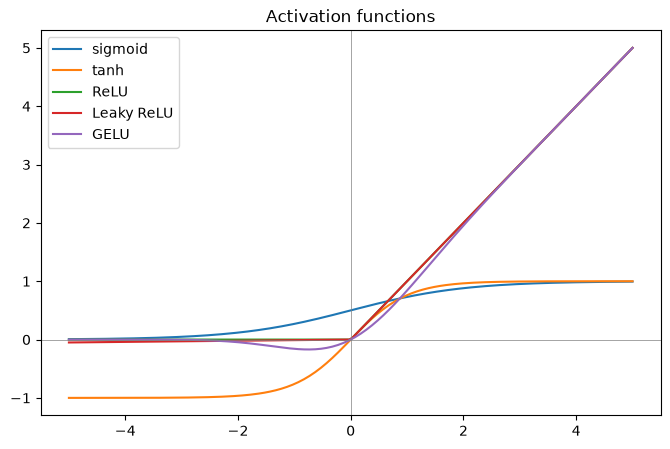

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def tanh(z):
    return np.tanh(z)

def leaky_relu(z, alpha=0.01):
    return np.where(z > 0, z, alpha * z)

def gelu(z):
    # Smooth approximation using the Gaussian CDF (the common practical form).
    return 0.5 * z * (1 + np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z**3)))

def softmax(z):
    # Numerically stable: subtract the max before exponentiating.
    z_shifted = z - np.max(z, axis=-1, keepdims=True)
    exp_z = np.exp(z_shifted)
    return exp_z / np.sum(exp_z, axis=-1, keepdims=True)

x_range = np.linspace(-5, 5, 200)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x_range, sigmoid(x_range), label="sigmoid")
ax.plot(x_range, tanh(x_range), label="tanh")
ax.plot(x_range, relu(x_range), label="ReLU")
ax.plot(x_range, leaky_relu(x_range), label="Leaky ReLU")
ax.plot(x_range, gelu(x_range), label="GELU")
ax.axhline(0, color="gray", linewidth=0.5); ax.axvline(0, color="gray", linewidth=0.5)
ax.legend(); ax.set_title("Activation functions")
plt.show()

# Sanity checks against known values.
assert np.isclose(sigmoid(0), 0.5)
assert np.isclose(tanh(0), 0.0)
assert relu(-5) == 0 and relu(5) == 5
assert leaky_relu(-10) < 0   # unlike ReLU, leaky ReLU doesn't fully zero out negatives


## 4. Softmax: a probability distribution over classes

💡 **Key Idea:** softmax's output ALWAYS sums to 1 across the class dimension, for each sample
independently -- never across the batch.

In [5]:
logits = rng.normal(scale=3, size=(4, 3))   # 4 samples, 3 classes each
probs = softmax(logits)
print("probabilities:\n", probs.round(3))
print("\nsum across classes per sample (should all be 1.0):", probs.sum(axis=-1).round(6))

assert np.allclose(probs.sum(axis=-1), 1.0)
assert np.all(probs >= 0) and np.all(probs <= 1)

# Numerical stability check: naive softmax overflows on large logits, the stable version doesn't.
huge_logits = np.array([[1000.0, 1001.0, 1002.0]])
naive_softmax_result = np.exp(huge_logits) / np.sum(np.exp(huge_logits))
print("\nnaive softmax on huge logits:", naive_softmax_result)   # likely nan
print("stable softmax on huge logits:", softmax(huge_logits))      # well-behaved

assert not np.any(np.isnan(softmax(huge_logits)))


probabilities:
 [[0.257 0.453 0.29 ]
 [0.019 0.981 0.   ]
 [0.106 0.368 0.526]
 [0.109 0.002 0.889]]

sum across classes per sample (should all be 1.0): [1. 1. 1. 1.]

naive softmax on huge logits: [[nan nan nan]]
stable softmax on huge logits: [[0.09003057 0.24472847 0.66524096]]


/var/folders/r5/0g0px5mx64g37vt5_6xmg9lm0000gn/T/ipykernel_46565/2163124088.py:11: RuntimeWarning: overflow encountered in exp
  naive_softmax_result = np.exp(huge_logits) / np.sum(np.exp(huge_logits))
/var/folders/r5/0g0px5mx64g37vt5_6xmg9lm0000gn/T/ipykernel_46565/2163124088.py:11: RuntimeWarning: invalid value encountered in divide
  naive_softmax_result = np.exp(huge_logits) / np.sum(np.exp(huge_logits))


## 5. Loss functions: MSE, BCE, cross-entropy

**Equations:** `MSE = mean((y_pred - y)^2)`, `BCE = -mean(y*log(p) + (1-y)*log(1-p))`,
`CE = -mean(log(p_true_class))`

⚠️ **Common Mistake:** computing `log(0)` when a predicted probability is exactly 0 or 1 --
always clip probabilities away from the exact boundary first.

In [6]:
def mse_loss(y_pred, y_true):
    return np.mean((y_pred - y_true) ** 2)

def bce_loss(y_pred_prob, y_true, eps=1e-12):
    p = np.clip(y_pred_prob, eps, 1 - eps)   # avoid log(0)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def cross_entropy_loss(probs, true_class_indices, eps=1e-12):
    n = len(true_class_indices)
    p_true = np.clip(probs[np.arange(n), true_class_indices], eps, 1.0)
    return -np.mean(np.log(p_true))

# BCE sanity check: confident CORRECT prediction -> near-zero loss; confident WRONG -> huge loss.
confident_correct = bce_loss(np.array([0.99]), np.array([1]))
confident_wrong = bce_loss(np.array([0.01]), np.array([1]))
print(f"BCE, confident correct (p=0.99, y=1): {confident_correct:.4f}")
print(f"BCE, confident WRONG   (p=0.01, y=1): {confident_wrong:.4f}")
assert confident_correct < 0.1
assert confident_wrong > 3.0

# Cross-entropy sanity check using the softmax probabilities from section 4.
true_classes = np.array([0, 1, 2, 0])
ce = cross_entropy_loss(probs, true_classes)
print(f"\ncross-entropy loss on the 4-sample batch: {ce:.4f}")
assert ce > 0


BCE, confident correct (p=0.99, y=1): 0.0101
BCE, confident WRONG   (p=0.01, y=1): 4.6052

cross-entropy loss on the 4-sample batch: 1.0591


## 6. Connection to what's next

`16_backpropagation` computes the gradient of exactly this loss with respect to every weight
in this exact 2-layer MLP, using the chain rule -- first by hand on a tiny example, then via
PyTorch's `autograd` doing it automatically.

## 7. Interview questions
1. Why can't stacking purely linear layers increase model capacity, no matter how many layers you add?
2. Why is softmax always computed with a max-subtraction trick in practice?
3. Why does BCE penalize a confident wrong prediction so much more heavily than an uncertain wrong one?
4. What's the shape of a softmax layer's output for a batch of 32 samples and 10 classes, and what does each dimension mean?
5. Why might GELU be preferred over ReLU in a Transformer specifically?

## 8. Exercises
1. Implement a 3-layer MLP forward pass (two hidden layers) and verify all intermediate shapes.
2. Implement Leaky ReLU's gradient by hand (as a function of `z`) and verify it's never exactly 0 (unlike ReLU's gradient for negative inputs).
3. Compute cross-entropy loss for a batch where every prediction is correct with very high confidence, and verify the loss is close to 0.

## 9. Summary

✅ A neural network is weighted sums (`XW+b`) interleaved with non-linear activations, trained
by minimizing a loss (MSE/BCE/cross-entropy) via the gradient computed through backpropagation.
Next: `16_backpropagation`.